<a href="https://colab.research.google.com/github/leman973/Deep-Learning/blob/main/Pract_3_FNN_Fashion_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Flatten,Input,Dropout

In [3]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [4]:
print("Training data shape",x_train.shape)
print("Testing data shape", x_test.shape)

Training data shape (60000, 28, 28)
Testing data shape (10000, 28, 28)


In [5]:
x_train = x_train/255.0
x_test = x_test/255.0

In [25]:
model = keras.Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(128,activation = "relu"),
    Dropout(0.3),
    Dense(64,activation="relu"),
    Dropout(0.3),
    Dense(10,activation="softmax")
])

In [26]:
history = model.compile(optimizer = "adam", loss = "sparse_categorical_crossentropy", metrics= ["accuracy"])

In [27]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
history = model.fit(x_train,y_train, epochs = 20, batch_size=32, validation_split = 0.1)

Epoch 1/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8801 - loss: 0.3237 - val_accuracy: 0.8845 - val_loss: 0.3270
Epoch 2/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8852 - loss: 0.3128 - val_accuracy: 0.8822 - val_loss: 0.3266
Epoch 3/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8845 - loss: 0.3111 - val_accuracy: 0.8835 - val_loss: 0.3268
Epoch 4/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8872 - loss: 0.3044 - val_accuracy: 0.8782 - val_loss: 0.3485
Epoch 5/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8893 - loss: 0.3006 - val_accuracy: 0.8878 - val_loss: 0.3192
Epoch 6/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8900 - loss: 0.2965 - val_accuracy: 0.8848 - val_loss: 0.3311
Epoch 7/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8906 - loss: 0.2994 - val_accuracy: 0.8873 - val_loss: 0.3131
Epoch 8/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8904 - loss: 0.2950 - 

In [31]:
test_loss,test_accuracy = model.evaluate(x_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8872 - loss: 0.3397


In [34]:
predict = model.predict(x_test)
prediction = np.argmax(predict,axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step   


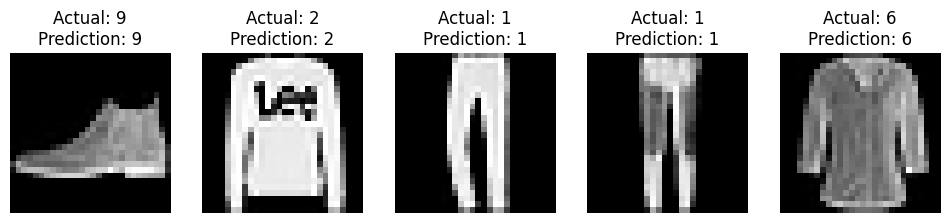

In [35]:
plt.figure(figsize=(12,5))
for i in range(5):
  plt.subplot(1,5,i+1)
  plt.imshow(x_test[i].reshape(28,28),cmap="gray")
  plt.title(f"Actual: {y_test[i]}\nPrediction: {prediction[i]}")
  plt.axis("off")
plt.show()


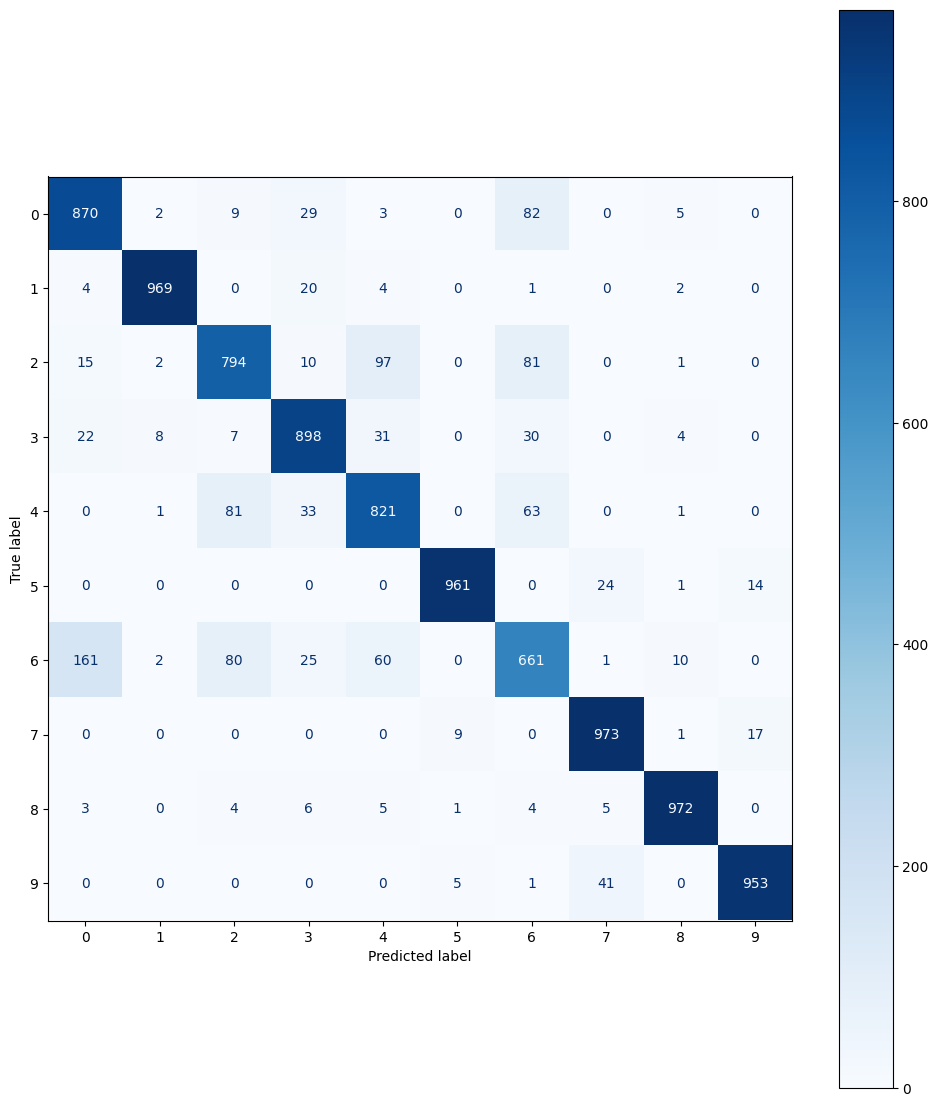

In [38]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
plt.figure(figsize=(12,14))
cm = confusion_matrix(y_test,prediction)
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues",ax = plt.gca())
plt.show()